In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import numpy as np, pandas as pd, random, warnings
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score

SEED = 0
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = "/content/drive/MyDrive"
TARGET = "rentals"
WEATHER = ["temperature", "precipitation", "humidity", "wind_speed"]

train_all = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["datetime"])
test_df   = pd.read_csv(f"{DATA_DIR}/test.csv",  parse_dates=["datetime"])
VAL_START = pd.Timestamp("2026-05-01")
tr_raw = train_all[train_all["datetime"] <  VAL_START]
va_raw = train_all[train_all["datetime"] >= VAL_START]

def add_features(df):
    d = df.copy()
    dt = d["datetime"]
    d["hour"] = dt.dt.hour
    d["dow"] = dt.dt.dayofweek
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    d["is_offday"] = ((d["is_weekend"] == 1) | (d["is_holiday"] == 1)).astype(int)
    for k in (1, 2):
        d[f"hour_sin{k}"] = np.sin(2 * np.pi * k * d["hour"] / 24)
        d[f"hour_cos{k}"] = np.cos(2 * np.pi * k * d["hour"] / 24)
    d["peak"] = np.select([d["hour"].between(7, 9), d["hour"].between(17, 19)], ["am", "pm"], "off")
    d["station"] = d["station"].astype(str)
    d["district"] = d["district"].astype(str)
    d["daytype_hour"] = d["is_offday"].astype(str) + "_" + d["hour"].astype(str)          # hour profile per day type
    d["station_peak"] = d["station"] + "_" + d["peak"] + "_" + d["is_offday"].astype(str)  # commute direction per station
    d["rain_flag"] = (d["precipitation"] > 0).astype(int)
    d["precip_peak"] = d["precipitation"] * (d["peak"] != "off")
    d["temp_sq"] = d["temperature"] ** 2
    return d

tr, va, te = add_features(tr_raw), add_features(va_raw), add_features(test_df)

S1_num = WEATHER + ["is_holiday"]
S1_cat = ["hour", "dow"]
S2_num = S1_num + ["capacity"]
S2_cat = S1_cat + ["station", "district"]
S3_num = S2_num + ["rain_flag", "precip_peak", "temp_sq"]
S3_cat = S2_cat + ["daytype_hour", "station_peak"]
FS = {
    "S0 baseline (weather)": (WEATHER, []),
    "S1 + time (hour, weekday, holiday)": (S1_num, S1_cat),
    "S2 + station (id, district, capacity)": (S2_num, S2_cat),
    "S3 + interactions (rain, day-type x hour, station x peak)": (S3_num, S3_cat),
}

USE_LOG = True

def safe_expm1(z):
    return np.expm1(np.clip(z, -5, 8))

def wrap(pipe, log=None):
    log = USE_LOG if log is None else log
    if log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=safe_expm1)
    return TransformedTargetRegressor(regressor=pipe, func=None, inverse_func=None)

def make_pipe(num, cat, model, scaler="standard"):
    sc = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}[scaler]
    tf = [("num", sc, num)]
    if cat:
        tf.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return Pipeline([("prep", ColumnTransformer(tf)), ("model", model)])

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

def fit_eval(pipe, num, cat, data_tr=None, data_va=None, log=None):
    data_tr = tr if data_tr is None else data_tr
    data_va = va if data_va is None else data_va
    cols = num + cat
    m = wrap(pipe, log).fit(data_tr[cols], data_tr[TARGET])
    ptr = np.clip(m.predict(data_tr[cols]), 0, None)
    pva = np.clip(m.predict(data_va[cols]), 0, None)
    n_feat = m.regressor_.named_steps["prep"].get_feature_names_out().shape[0]
    return m, dict(n_features=n_feat,
                   train_RMSE=rmse(data_tr[TARGET], ptr),
                   val_RMSE=rmse(data_va[TARGET], pva),
                   val_R2=float(r2_score(data_va[TARGET], pva)))

from sklearn.model_selection import learning_curve

def plot_learning_curve(model, X, y, cv=5, train_sizes=np.linspace(0.1, 1.0, 5), ax=None, title="Learning Curve", ylim=None):
    sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, train_sizes=train_sizes,
        scoring="neg_root_mean_squared_error", n_jobs=-1)
    train_rmse = -train_scores.mean(axis=1)
    val_rmse = -val_scores.mean(axis=1)
    if ax is None:
        plt.figure(figsize=(7, 5)); ax = plt.gca()
    ax.plot(sizes, train_rmse, marker="o", label="Training RMSE")
    ax.plot(sizes, val_rmse, marker="o", label="Validation RMSE")
    ax.set(xlabel="Number of training examples", ylabel="RMSE", title=title)
    ax.legend(); ax.grid(alpha=0.3)
    if ylim: ax.set_ylim(*ylim)
    return sizes, train_rmse, val_rmse

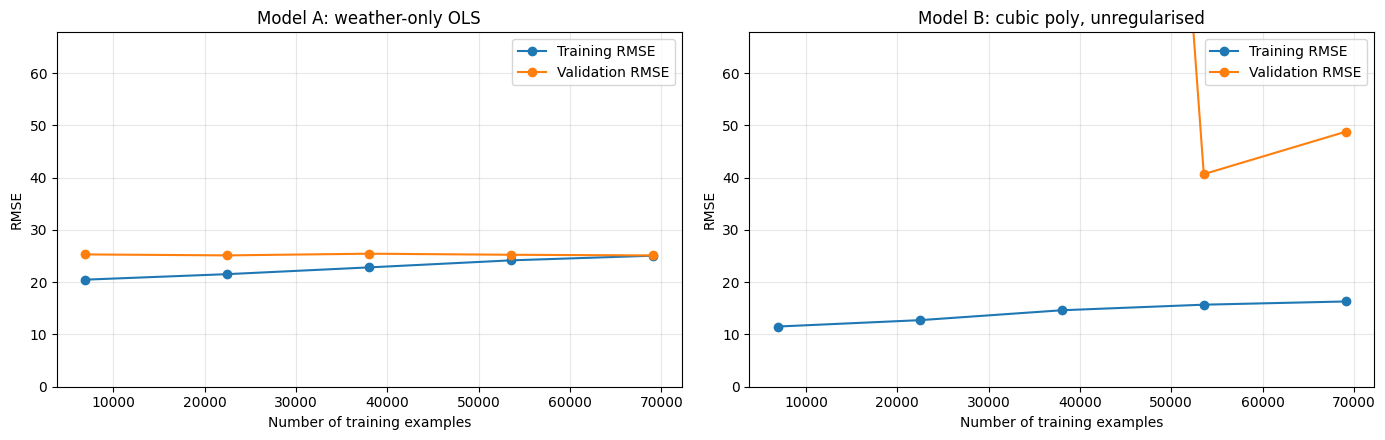

Model A: final train RMSE=25.070, final CV RMSE=25.116, gap=0.046
Model B: final train RMSE=16.310, final CV RMSE=48.791, gap=32.481
A val RMSE 29.374502716212696
B val RMSE 24.38067596911725


In [4]:
Xtr_all = tr.copy()
ytr_all = tr[TARGET]
ycap = (0, 2.5 * ytr_all.std())

A_num, A_cat = WEATHER, []
modelA = wrap(make_pipe(A_num, A_cat, LinearRegression()), log=False)

B_num = WEATHER + ["capacity", "is_offday", "hour_sin1", "hour_cos1", "hour_sin2", "hour_cos2"]
B_cat = ["station"]
def make_poly(num, cat, model, degree=3):
    prep = ColumnTransformer([
        ("num", Pipeline([("sc", StandardScaler()), ("poly", PolynomialFeatures(degree, include_bias=False))]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return Pipeline([("prep", prep), ("model", model)])
modelB = wrap(make_poly(B_num, B_cat, LinearRegression()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
curves = {}
curves["A"] = plot_learning_curve(modelA, Xtr_all[A_num + A_cat], ytr_all, title="Model A: weather-only OLS", ax=ax[0], ylim=ycap)
curves["B"] = plot_learning_curve(modelB, Xtr_all[B_num + B_cat], ytr_all, title="Model B: cubic poly, unregularised", ax=ax[1], ylim=ycap)
plt.tight_layout(); plt.show()

for k, v in curves.items():
    if v is not None:
        _, trc, vac = v
        print(f"Model {k}: final train RMSE={trc[-1]:.3f}, final CV RMSE={vac[-1]:.3f}, gap={vac[-1]-trc[-1]:.3f}")
for k, (mod, n, c) in {"A": (modelA, A_num, A_cat), "B": (modelB, B_num, B_cat)}.items():
    mod.fit(tr[n + c], tr[TARGET]); print(k, "val RMSE", rmse(va[TARGET], np.clip(mod.predict(va[n + c]), 0, None)))

,alpha,val_RMSE
0,1.0,24.035699
1,10.0,22.282672
2,100.0,20.820180
3,1000.0,20.601695
4,10000.0,21.083577
5,100000.0,24.002082


best alpha: 1000.0


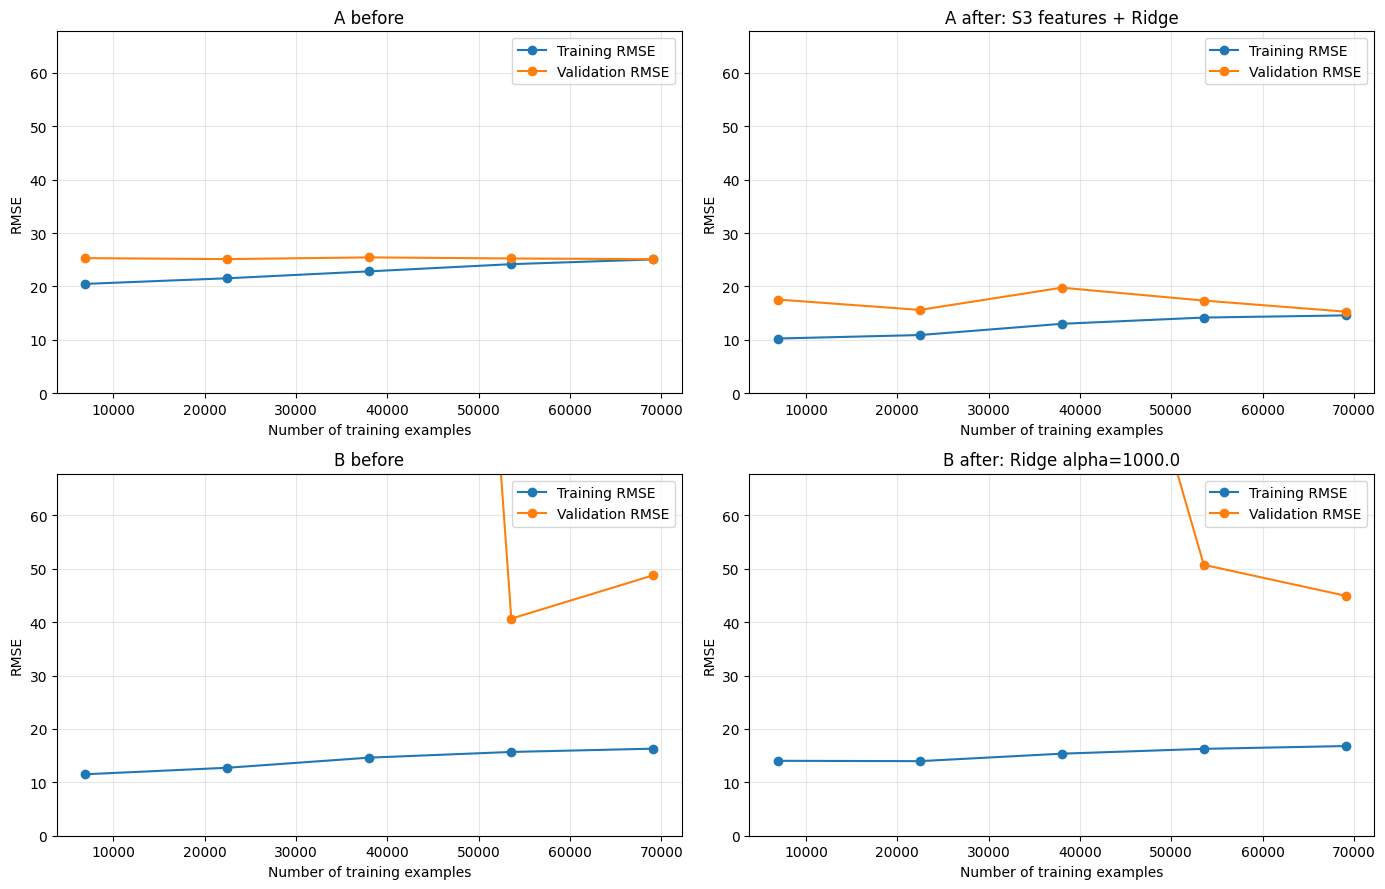

In [5]:
n3, c3 = FS[list(FS)[-1]]
modelA2 = wrap(make_pipe(n3, c3, Ridge(alpha=10)))

grid = [1, 10, 100, 1e3, 1e4, 1e5]
res = []
for a in grid:
    mB = wrap(make_poly(B_num, B_cat, Ridge(alpha=a))).fit(tr[B_num + B_cat], tr[TARGET])
    res.append((a, rmse(va[TARGET], np.clip(mB.predict(va[B_num + B_cat]), 0, None))))
display(pd.DataFrame(res, columns=["alpha", "val_RMSE"]))
best_alpha = min(res, key=lambda t: t[1])[0]; print("best alpha:", best_alpha)
modelB2 = wrap(make_poly(B_num, B_cat, Ridge(alpha=best_alpha)))

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
plot_learning_curve(modelA,  Xtr_all[A_num + A_cat], ytr_all, title="A before", ax=ax[0, 0], ylim=ycap)
plot_learning_curve(modelA2, Xtr_all[n3 + c3],       ytr_all, title="A after: S3 features + Ridge", ax=ax[0, 1], ylim=ycap)
plot_learning_curve(modelB,  Xtr_all[B_num + B_cat], ytr_all, title="B before", ax=ax[1, 0], ylim=ycap)
plot_learning_curve(modelB2, Xtr_all[B_num + B_cat], ytr_all, title=f"B after: Ridge alpha={best_alpha}", ax=ax[1, 1], ylim=ycap)
plt.tight_layout(); plt.show()

In [6]:
_, a_tr, a_va = plot_learning_curve(modelA2, Xtr_all[n3 + c3], ytr_all, title="A after", ax=ax[0, 1], ylim=ycap)
_, b_tr, b_va = plot_learning_curve(modelB2, Xtr_all[B_num + B_cat], ytr_all, title="B after", ax=ax[1, 1], ylim=ycap)
print("A after:", a_tr[-1], a_va[-1], "| B after:", b_tr[-1], b_va[-1])

A after: 14.580792746930754 15.27921328182951 | B after: 16.80018959583382 44.945152464075775


In [7]:
cands = {
  "Model A2 (S3 + Ridge10)": (make_pipe(n3, c3, Ridge(alpha=10)), n3, c3),
  "Model B":  (make_poly(B_num, B_cat, LinearRegression()), B_num, B_cat),
  f"Model B2 (poly + Ridge {best_alpha})": (make_poly(B_num, B_cat, Ridge(alpha=best_alpha)), B_num, B_cat),
}
for a in [0.1, 0.3, 1, 3, 10, 30, 100]:
    cands[f"S3 + Ridge {a}"] = (make_pipe(n3, c3, Ridge(alpha=a)), n3, c3)
for a in [1e-3, 1e-2]:
    cands[f"S3 + Lasso {a}"] = (make_pipe(n3, c3, Lasso(alpha=a, max_iter=20000)), n3, c3)

rows = []
_, r = fit_eval(make_pipe(WEATHER, [], LinearRegression()), WEATHER, [], log=False)
rows.append(dict(model="TA baseline (weather LR, raw target)", **r))
for k, (p, n, c) in cands.items():
    _, r = fit_eval(p, n, c); rows.append(dict(model=k, **r))
board = pd.DataFrame(rows).sort_values("val_RMSE"); display(board)
best = board[board["model"].isin(cands)].iloc[0]["model"]; print("selected:", best)

,model,n_features,train_RMSE,val_RMSE,val_R2
4,S3 + Ridge 0.1,307,14.617394,15.956653,0.734073
5,S3 + Ridge 0.3,307,14.618283,15.957883,0.734032
6,S3 + Ridge 1,307,14.621411,15.962194,0.733889
7,S3 + Ridge 3,307,14.630475,15.974558,0.733476
1,Model A2 (S3 + Ridge10),307,14.663444,16.018221,0.732017
8,S3 + Ridge 10,307,14.663444,16.018221,0.732017
9,S3 + Ridge 30,307,14.764294,16.143451,0.727811
10,S3 + Ridge 100,307,15.127494,16.550127,0.713924
11,S3 + Lasso 0.001,307,16.069304,17.684348,0.673370
3,Model B2 (poly + Ridge 1000.0),315,16.846937,20.601695,0.556714


selected: S3 + Ridge 0.1


In [8]:
full = add_features(train_all)
p, n, c = cands[best]
final = wrap(p).fit(full[n + c], full[TARGET])
pred = np.clip(final.predict(te[n + c]), 0, None)

sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
tcol = [col for col in sample.columns if col != "id"][0]
sub = sample.copy()
sub = sub[["id"]].merge(pd.DataFrame({"id": test_df["id"], tcol: pred}), on="id", how="left")
assert sub[tcol].notna().all() and len(sub) == len(sample)
sub.to_csv("submission.csv", index=False)
print(sub.head(), "\n", sub.shape)
from google.colab import files; files.download("submission.csv")

       id    rentals
0  108720   5.641076
1  108721   3.856856
2  108722   5.798495
3  108723   7.064557
4  108724  12.202007 
 (21600, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>